**Setup**

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, sys, importlib
REPO = "/content/anomaly-mvtec"
if not os.path.exists(REPO):
    !git clone https://github.com/maha-mrrk/anomaly-mvtec.git {REPO}
else:
    !git -C {REPO} pull
%cd {REPO}
if REPO not in sys.path:
    sys.path.append(REPO)
importlib.invalidate_caches()          # prend en compte les nouveaux fichiers après un pull
!pip install -q -r requirements.txt

from src.config import *
set_seed(42)
prepare_data()
print(device, DATA_ROOT)

Mounted at /content/drive
Cloning into '/content/anomaly-mvtec'...
remote: Enumerating objects: 82, done.
remote: Counting objects: 100% (82/82), done.
remote: Compressing objects: 100% (67/67), done.
remote: Total 82 (delta 28), reused 64 (delta 13), pack-reused 0 (from 0)
Receiving objects: 100% (82/82), 14.03 MiB | 33.87 MiB/s, done.
Resolving deltas: 100% (28/28), done.
/content/anomaly-mvtec
Données prêtes : ['carpet', 'screw', 'cable']
cuda /content/mvtec


**Imports**

In [2]:
import time, numpy as np, pandas as pd, matplotlib.pyplot as plt, torch, torch.nn.functional as F
import torchvision.transforms.functional as TF
from torch.utils.data import DataLoader
from src.data import *
from src.scoring import *
from src.metrics import image_auroc
from src.models.dino import DinoDetector
from src.models.vae import ConvVAE, vae_loss
from src.models.simsiam import SimSiam

EPS_LIST, PGD_STEPS = [1, 2, 4, 8], 10      # ε en /255 ; 20 pas pour la version finale si le temps le permet
TOPK_FRAC, SIGMA, K_Q = 0.01, 4, 95
MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)
RES_DIR = f"{REPO}/results"; os.makedirs(RES_DIR, exist_ok=True)
det = DinoDetector("dino_vits8", 224, device)

Downloading: "https://github.com/facebookresearch/dino/zipball/main" to /root/.cache/torch/hub/main.zip
Downloading: "https://dl.fbaipublicfiles.com/dino/dino_deitsmall8_pretrain/dino_deitsmall8_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dino_deitsmall8_pretrain.pth


100%|██████████| 82.7M/82.7M [00:02<00:00, 35.4MB/s]


**Cellule 3 : les trois détecteurs, avec une carte différentiable**

In [3]:
@torch.no_grad()
def nn_index(q, bank, chunk=1024):
    return torch.cat([torch.cdist(q[i:i + chunk], bank).argmin(1) for i in range(0, len(q), chunk)])

def to_map(q, bank, B, h, w, size):
    idx = nn_index(q.detach(), bank)
    d = ((q - bank[idx]) ** 2).sum(1).add(1e-12).sqrt().reshape(B, 1, h, w)
    return F.interpolate(d, size=(size, size), mode="bilinear", align_corners=False)[:, 0]

class DinoWrap:
    size = 224
    def __init__(self, det): self.det = det
    def fit(self, cat):
        tr, _ = list_train_val(DATA_ROOT, cat)
        self.det.fit(DataLoader(MVTecDataset(tr, 224, imagenet_norm=True), batch_size=32))
    def map(self, x01):
        f = self.det.patch_features((x01 - MEAN) / STD)
        B, N, D = f.shape
        return to_map(f.reshape(-1, D), self.det.bank, B, self.det.grid, self.det.grid, 224)

class SimSiamWrap:
    size = 224
    def __init__(self, cat, tag="SimSiam-ImageNet"):
        self.m = SimSiam(pretrained=False).to(device)
        self.m.load_state_dict(torch.load(f"{CKPT_DIR}/{tag}_{cat}.pt", map_location=device)); self.m.eval()
        for p in self.m.parameters(): p.requires_grad_(False)
        tr, _ = list_train_val(DATA_ROOT, cat)
        dl = DataLoader(MVTecDataset(tr, 224, imagenet_norm=True), batch_size=32)
        with torch.no_grad():
            f3 = torch.cat([self.m.features(x.to(device))[0] for x, _, _ in dl])
        self.bank = f3.permute(0, 2, 3, 1).reshape(-1, f3.shape[1])
    def map(self, x01):
        f3 = self.m.features((x01 - MEAN) / STD)[0]
        B, C, h, w = f3.shape
        return to_map(f3.permute(0, 2, 3, 1).reshape(-1, C), self.bank, B, h, w, 224)

class VaeWrap:
    size = 128
    def __init__(self, cat, tag="VAE_beta0.01"):
        self.m = ConvVAE(128).to(device)
        self.m.load_state_dict(torch.load(f"{CKPT_DIR}/{tag}_{cat}.pt", map_location=device)); self.m.eval()
        for p in self.m.parameters(): p.requires_grad_(False)
    def map(self, x01):
        return ((x01 - self.m(x01)[0]) ** 2).mean(dim=1)

**Cellule 4 : attaques et évaluation**

In [4]:
def attack_score(maps):                          # score différentiable minimisé par l'attaquant
    flat = maps.flatten(1); k = max(1, int(TOPK_FRAC * flat.shape[1]))
    return flat.topk(k, dim=1).values.mean(1)

def fgsm(model, x, eps):
    x = x.clone().requires_grad_(True)
    g, = torch.autograd.grad(attack_score(model.map(x)).sum(), x)
    return (x.detach() - eps * g.sign()).clamp(0, 1)

def pgd(model, x, eps, steps=PGD_STEPS):
    alpha, xa = 2.5 * eps / steps, x.clone()
    for _ in range(steps):
        xa.requires_grad_(True)
        g, = torch.autograd.grad(attack_score(model.map(xa)).sum(), xa)
        xa = xa.detach() - alpha * g.sign()                       # on DESCEND le score : le défaut est masqué
        xa = torch.min(torch.max(xa, x - eps), x + eps).clamp(0, 1)
    return xa.detach()

@torch.no_grad()
def eval_maps(model, X, bs=16):
    return np.concatenate([model.map(X[i:i + bs].to(device)).cpu().numpy() for i in range(0, len(X), bs)])

def run_attacks(model, cat, attacks=("FGSM", "PGD"), bs=8):
    items = list_test(DATA_ROOT, cat)
    ds = MVTecDataset(items, model.size)                          # [0,1], sans normalisation
    X = torch.stack([ds[i][0] for i in range(len(ds))])
    y = np.array([l for _, l, _ in items]); bad = np.where(y == 1)[0]
    _, val = list_train_val(DATA_ROOT, cat)
    dv = MVTecDataset(val, model.size); Xv = torch.stack([dv[i][0] for i in range(len(dv))])
    scores = lambda Xs: image_scores_from_maps(smooth_maps(eval_maps(model, Xs), SIGMA))
    thr = np.percentile(scores(Xv), K_Q)                          # seuil P95(val_normal), fixé avant l'attaque
    s0 = scores(X); det0 = s0[bad] > thr
    rows = [dict(category=cat, attack="none", eps=0, img_auroc=image_auroc(y, s0),
                 TPR=det0.mean(), masked=0.0)]
    for atk in attacks:
        f = fgsm if atk == "FGSM" else pgd
        for e in EPS_LIST:
            Xa = torch.cat([f(model, X[bad[i:i + bs]].to(device), e / 255).cpu()
                            for i in range(0, len(bad), bs)])
            s = s0.copy(); s[bad] = scores(Xa)                    # seules les images défectueuses sont attaquées
            rows.append(dict(category=cat, attack=atk, eps=e, img_auroc=image_auroc(y, s),
                             TPR=(s[bad] > thr).mean(),
                             masked=(det0 & (s[bad] <= thr)).sum() / max(1, det0.sum())))
    return rows

**Cellule 5 : grand run**

In [5]:
ALL = []
for cat in CATEGORIES:
    dino = DinoWrap(det); dino.fit(cat)
    for name, m in {"DINO": dino, "SimSiam-ImageNet": SimSiamWrap(cat), "VAE": VaeWrap(cat)}.items():
        t0 = time.time(); rows = run_attacks(m, cat)
        ALL += [{"model": name, **r} for r in rows]
        r8 = [r for r in rows if r["attack"] == "PGD" and r["eps"] == 8][0]
        print(f"{cat:7s} {name:17s} | propre {rows[0]['img_auroc']:.3f} -> PGD 8/255 {r8['img_auroc']:.3f} | {time.time()-t0:.0f}s")
df = pd.DataFrame(ALL); df.to_csv(f"{RES_DIR}/t11_attacks.csv", index=False)
df.round(3)

carpet  DINO              | propre 0.997 -> PGD 8/255 0.189 | 554s
carpet  SimSiam-ImageNet  | propre 0.511 -> PGD 8/255 0.232 | 36s
carpet  VAE               | propre 0.547 -> PGD 8/255 0.292 | 15s
screw   DINO              | propre 0.943 -> PGD 8/255 0.401 | 790s
screw   SimSiam-ImageNet  | propre 0.810 -> PGD 8/255 0.926 | 42s
screw   VAE               | propre 0.631 -> PGD 8/255 0.297 | 12s
cable   DINO              | propre 0.983 -> PGD 8/255 0.454 | 532s
cable   SimSiam-ImageNet  | propre 0.909 -> PGD 8/255 0.266 | 35s
cable   VAE               | propre 0.699 -> PGD 8/255 0.308 | 15s


,model,category,attack,eps,img_auroc,TPR,masked
0,DINO,carpet,none,0,0.997,0.989,0.000
1,DINO,carpet,FGSM,1,0.957,0.933,0.057
2,DINO,carpet,FGSM,2,0.956,0.921,0.068
3,DINO,carpet,FGSM,4,0.992,0.989,0.000
4,DINO,carpet,FGSM,8,1.000,1.000,0.000
...,...,...,...,...,...,...,...
76,VAE,cable,FGSM,8,0.455,0.011,0.955
77,VAE,cable,PGD,1,0.629,0.196,0.182
78,VAE,cable,PGD,2,0.559,0.130,0.455
79,VAE,cable,PGD,4,0.445,0.098,0.591


**Cellule 6 : courbes**

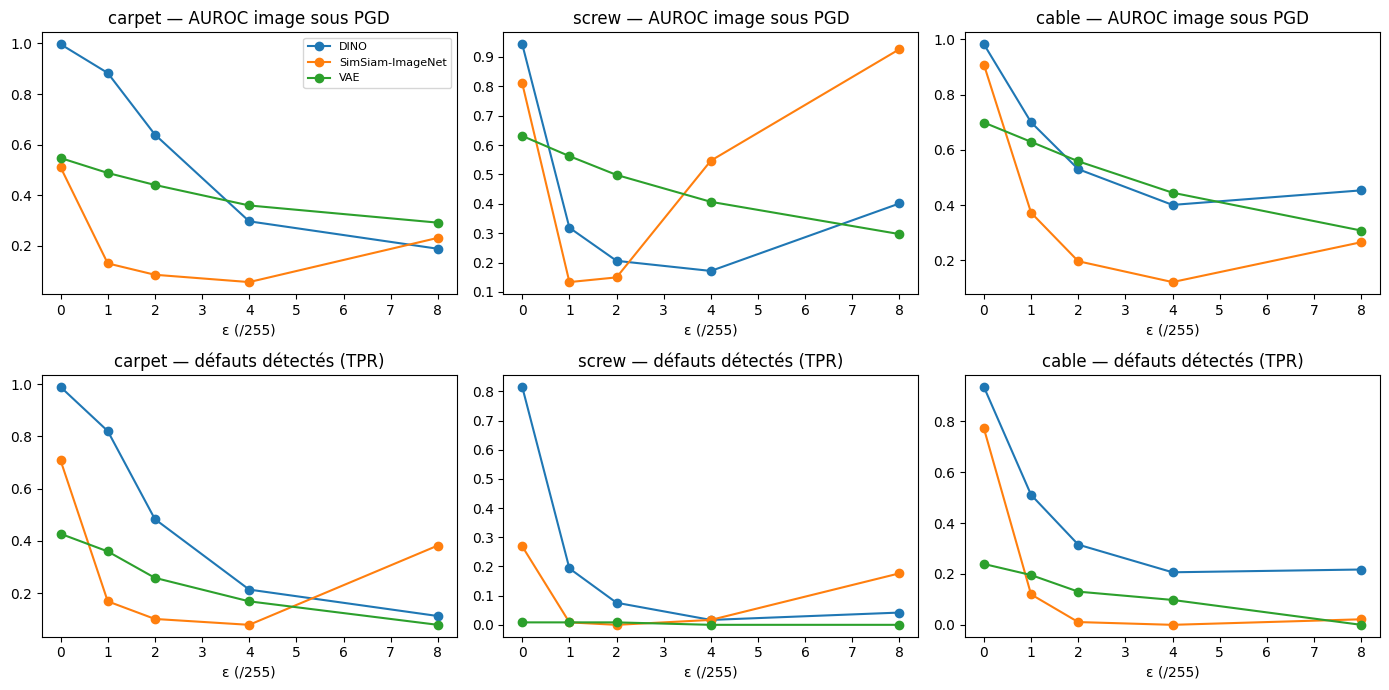

In [6]:
fig, ax = plt.subplots(2, 3, figsize=(14, 7))
for c, cat in enumerate(CATEGORIES):
    for name in df.model.unique():
        d = df[(df.model == name) & (df.category == cat)]
        p, c0 = d[d.attack == "PGD"], d[d.attack == "none"].iloc[0]
        ax[0, c].plot([0] + list(p.eps), [c0.img_auroc] + list(p.img_auroc), "o-", label=name)
        ax[1, c].plot([0] + list(p.eps), [c0.TPR] + list(p.TPR), "o-", label=name)
    ax[0, c].set_title(f"{cat} — AUROC image sous PGD"); ax[1, c].set_title(f"{cat} — défauts détectés (TPR)")
    for r in range(2): ax[r, c].set_xlabel("ε (/255)")
ax[0, 0].legend(fontsize=8); plt.tight_layout()
plt.savefig(f"{RES_DIR}/t11_attack_curves.png", dpi=150); plt.show()

**Cellule 7 : exemple visuel d’un défaut masqué (pour le rapport)**

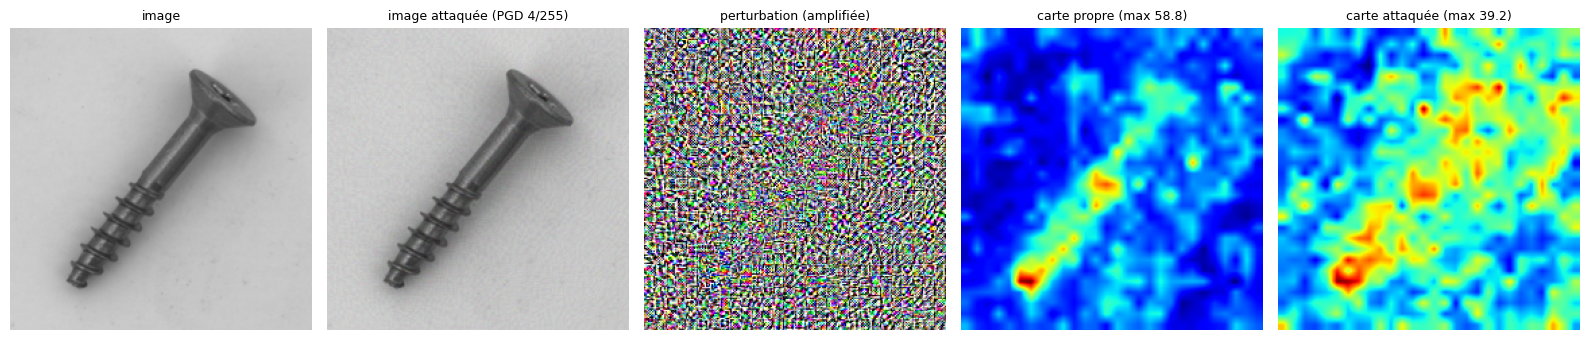

In [7]:
cat = "screw"; m = DinoWrap(det); m.fit(cat)
ds = MVTecDataset(list_test(DATA_ROOT, cat), 224)
i = [k for k, (_, l, _) in enumerate(ds.items) if l == 1][0]
x = ds[i][0][None].to(device); xa = pgd(m, x, 4 / 255)
with torch.no_grad(): mc, ma = m.map(x)[0].cpu(), m.map(xa)[0].cpu()
fig, ax = plt.subplots(1, 5, figsize=(16, 3.5))
for a, im, t, cm in zip(ax, [x[0].permute(1, 2, 0).cpu(), xa[0].permute(1, 2, 0).cpu(),
                             ((xa - x)[0] * 255 / 4 / 2 + 0.5).permute(1, 2, 0).cpu(), mc, ma],
                        ["image", "image attaquée (PGD 4/255)", "perturbation (amplifiée)",
                         f"carte propre (max {mc.max():.1f})", f"carte attaquée (max {ma.max():.1f})"],
                        [None, None, None, "jet", "jet"]):
    a.imshow(im, cmap=cm); a.set_title(t, fontsize=9); a.axis("off")
plt.tight_layout(); plt.savefig(f"{RES_DIR}/t11_example.png", dpi=150); plt.show()

**(a) VAE débruiteur (bruit gaussien à l’entraînement) :**

In [8]:
def train_vae_dn(cat, beta=0.01, noise=0.05, epochs=150, bs=32, lr=1e-3):
    set_seed()
    tr, _ = list_train_val(DATA_ROOT, cat)
    ds = MVTecDataset(tr, 128); X = torch.stack([ds[i][0] for i in range(len(ds))]).to(device)
    model = ConvVAE(128).to(device); opt = torch.optim.Adam(model.parameters(), lr=lr)
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(X), device=device)
        for i in range(0, len(X) - bs + 1, bs):
            x = X[perm[i:i + bs]]
            xr, mu, lv = model((x + noise * torch.randn_like(x)).clamp(0, 1))   # entrée bruitée, cible propre
            loss, _, _ = vae_loss(x, xr, mu, lv, beta)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
    torch.save(model.eval().state_dict(), f"{CKPT_DIR}/VAEdn_beta{beta}_{cat}.pt")
for cat in CATEGORIES: train_vae_dn(cat)

**(b) DINO avec flou d’entrée (le flou est différentiable, donc l’attaque le « voit ») :**

In [10]:
class Blurred:
    def __init__(self, base, sigma=1.0): self.base, self.sigma, self.size = base, sigma, base.size
    def map(self, x): return self.base.map(TF.gaussian_blur(x, kernel_size=5, sigma=self.sigma))

DEF = []
for cat in CATEGORIES:
    dino = DinoWrap(det); dino.fit(cat)
    for name, m in {"VAE-débruiteur": VaeWrap(cat, "VAEdn_beta0.01"), "DINO+flou": Blurred(dino)}.items():
        DEF += [{"model": name, **r} for r in run_attacks(m, cat, attacks=("PGD",))]
dfd = pd.DataFrame(DEF); dfd.to_csv(f"{RES_DIR}/t11_defenses.csv", index=False)
dfd.round(3)

,model,category,attack,eps,img_auroc,TPR,masked
0,VAE-débruiteur,carpet,none,0,0.550,0.461,0.000
1,VAE-débruiteur,carpet,PGD,1,0.506,0.404,0.122
2,VAE-débruiteur,carpet,PGD,2,0.460,0.337,0.268
3,VAE-débruiteur,carpet,PGD,4,0.390,0.213,0.537
4,VAE-débruiteur,carpet,PGD,8,0.312,0.135,0.707
5,DINO+flou,carpet,none,0,0.994,0.989,0.000
6,DINO+flou,carpet,PGD,1,0.897,0.719,0.273
7,DINO+flou,carpet,PGD,2,0.666,0.348,0.648
8,DINO+flou,carpet,PGD,4,0.315,0.180,0.818
9,DINO+flou,carpet,PGD,8,0.182,0.079,0.920


In [11]:
%cd /content/anomaly-mvtec
!ls results | grep t11_
!zip -o /content/results06.zip results/t11_*
from google.colab import files
files.download("/content/results06.zip")

/content/anomaly-mvtec
t11_attack_curves.png
t11_attacks.csv
t11_defenses.csv
t11_example.png
  adding: results/t11_attack_curves.png (deflated 7%)
  adding: results/t11_attacks.csv (deflated 69%)
  adding: results/t11_defenses.csv (deflated 64%)
  adding: results/t11_example.png (deflated 0%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>